In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00352/Online%20Retail.xlsx"
)

df = pd.read_excel(url)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (541909, 8)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Work with a copy of the original dataset
retail = df.copy()

# Convert relevant columns to appropriate types
retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"])
retail["InvoiceNo"] = retail["InvoiceNo"].astype(str)

# Keep UK transactions for a consistent market scope
retail = retail[retail["Country"] == "United Kingdom"].copy()

# Remove cancelled invoices (invoice numbers beginning with C)
retail = retail[
    ~retail["InvoiceNo"].str.startswith("C")
].copy()

# Keep positive sales quantities and valid prices
retail = retail[
    (retail["Quantity"] > 0) &
    (retail["UnitPrice"] > 0)
].copy()

print("Cleaned dataset shape:", retail.shape)
print("Date range:")
print(retail["InvoiceDate"].min(), "to", retail["InvoiceDate"].max())

display(retail.head())

Cleaned dataset shape: (485123, 8)
Date range:
2010-12-01 08:26:00 to 2011-12-09 12:49:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
daily_demand = (
    retail.set_index("InvoiceDate")["Quantity"]
    .resample("D")
    .sum()
    .rename("Demand")
    .to_frame()
)

# Fill calendar days with no recorded sales
daily_demand["Demand"] = daily_demand["Demand"].fillna(0)

print("Daily observations:", len(daily_demand))
print("\nDaily demand summary:")
display(daily_demand["Demand"].describe().round(2))

display(daily_demand.head(10))

Daily observations: 374

Daily demand summary:


,Demand
count,374.00
mean,12466.28
std,10458.52
min,0.00
25%,5986.50
50%,11262.00
75%,17613.00
max,90564.00


,Demand
InvoiceDate,
2010-12-01,24014
2010-12-02,31175
2010-12-03,11808
2010-12-04,0
2010-12-05,13660
2010-12-06,21039
2010-12-07,23994
2010-12-08,20459
2010-12-09,16023


In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Work on a copy of the daily demand series
model_data = daily_demand.copy()

# Calendar features
model_data["DayOfWeek"] = model_data.index.dayofweek
model_data["Month"] = model_data.index.month
model_data["DayOfMonth"] = model_data.index.day
model_data["IsWeekend"] = (model_data["DayOfWeek"] >= 5).astype(int)

# Lag features: demand from previous days
model_data["Lag_1"] = model_data["Demand"].shift(1)
model_data["Lag_7"] = model_data["Demand"].shift(7)
model_data["Lag_14"] = model_data["Demand"].shift(14)

# Rolling averages use past demand only, avoiding target leakage
model_data["RollingMean_7"] = (
    model_data["Demand"].shift(1).rolling(window=7).mean()
)
model_data["RollingMean_14"] = (
    model_data["Demand"].shift(1).rolling(window=14).mean()
)

# Remove rows without enough historical observations
model_data = model_data.dropna()

print("Model dataset shape:", model_data.shape)
display(model_data.head())


Model dataset shape: (360, 10)


,Demand,DayOfWeek,Month,DayOfMonth,IsWeekend,Lag_1,Lag_7,Lag_14,RollingMean_7,RollingMean_14
InvoiceDate,,,,,,,,,,
2010-12-15,18359,2,12,15,0,19127.0,20459.0,24014.0,14328.714286,16142.214286
2010-12-16,28328,3,12,16,0,18359.0,16023.0,31175.0,14028.714286,15738.285714
2010-12-17,9701,4,12,17,0,28328.0,19073.0,11808.0,15786.571429,15534.928571
2010-12-18,0,5,12,18,1,9701.0,0.0,0.0,14447.714286,15384.428571
2010-12-19,3307,6,12,19,1,0.0,8194.0,13660.0,14447.714286,15384.428571


In [6]:

features = [
    "DayOfWeek", "Month", "DayOfMonth", "IsWeekend",
    "Lag_1", "Lag_7", "Lag_14",
    "RollingMean_7", "RollingMean_14"
]

X = model_data[features]
y = model_data["Demand"]

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", X_train.index.min().date(), "to", X_train.index.max().date())
print("Testing period:", X_test.index.min().date(), "to", X_test.index.max().date())


Training rows: 288
Testing rows: 72
Training period: 2010-12-15 to 2011-09-28
Testing period: 2011-09-29 to 2011-12-09


In [7]:

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_predictions = X_test["RollingMean_7"].to_numpy()

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

results = []
predictions = {}

def evaluate_model(name, actual, predicted):
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

evaluate_model("7-Day Average Baseline", y_test, baseline_predictions)

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    evaluate_model(name, y_test, predictions[name])

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df.round(2))


,Model,MAE,RMSE,R2
1,Random Forest,6474.29,9969.75,0.46
2,Gradient Boosting,7818.77,10615.40,0.39
0,7-Day Average Baseline,9175.57,13097.21,0.07


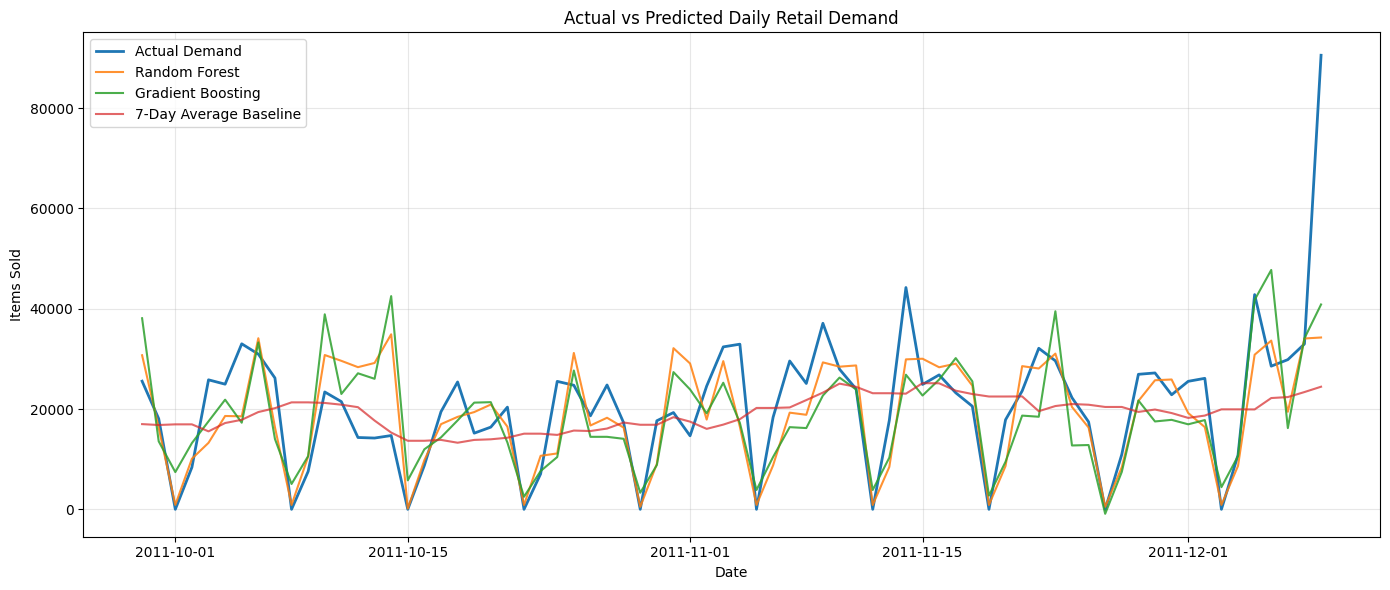

In [8]:

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index, y_test.values,
    label="Actual Demand", linewidth=2
)

plt.plot(
    y_test.index, predictions["Random Forest"],
    label="Random Forest", alpha=0.85
)

plt.plot(
    y_test.index, predictions["Gradient Boosting"],
    label="Gradient Boosting", alpha=0.85
)

plt.plot(
    y_test.index, baseline_predictions,
    label="7-Day Average Baseline", alpha=0.7
)

plt.title("Actual vs Predicted Daily Retail Demand")
plt.xlabel("Date")
plt.ylabel("Items Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


,Importance
Lag_7,0.4169
DayOfWeek,0.1607
Lag_1,0.1165
IsWeekend,0.0852
Lag_14,0.0572
DayOfMonth,0.0442
RollingMean_14,0.0400
Month,0.0397
RollingMean_7,0.0396


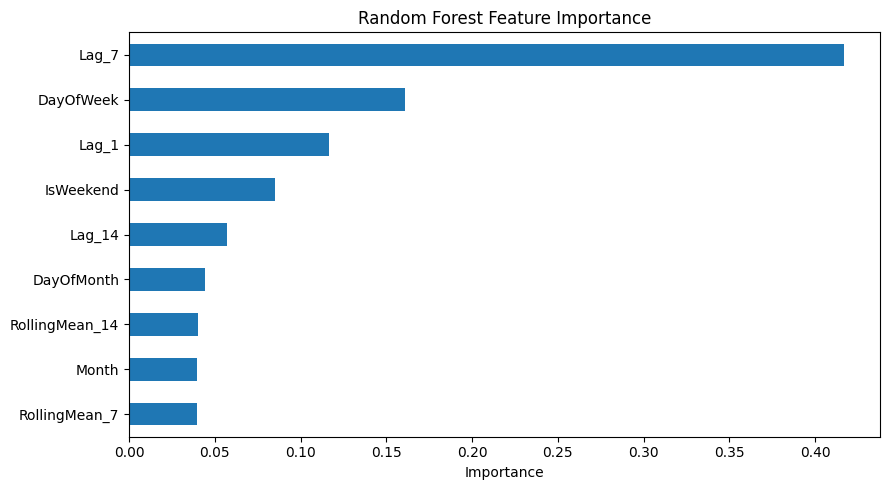

In [9]:

rf_model = models["Random Forest"]

importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

display(importance.to_frame("Importance").round(4))

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [10]:

# Compare actual and predicted demand on the test period
forecast_errors = y_test.to_numpy() - predictions["Random Forest"]

mae = mean_absolute_error(y_test, predictions["Random Forest"])
error_std = np.std(forecast_errors, ddof=1)

# Illustrative inventory assumptions
lead_time_days = 3
service_level_z = 1.645  # Approx. 95% one-sided service level

average_daily_forecast = np.mean(predictions["Random Forest"])

safety_stock = service_level_z * error_std * np.sqrt(lead_time_days)
lead_time_demand = average_daily_forecast * lead_time_days
reorder_point = lead_time_demand + safety_stock

print(f"Test MAE: {mae:,.0f} items/day")
print(f"Forecast error standard deviation: {error_std:,.0f}")
print(f"Assumed lead time: {lead_time_days} days")
print(f"Estimated lead-time demand: {lead_time_demand:,.0f} items")
print(f"Estimated safety stock: {safety_stock:,.0f} items")
print(f"Illustrative reorder point: {reorder_point:,.0f} items")


Test MAE: 6,474 items/day
Forecast error standard deviation: 9,880
Assumed lead time: 3 days
Estimated lead-time demand: 56,839 items
Estimated safety stock: 28,151 items
Illustrative reorder point: 84,990 items


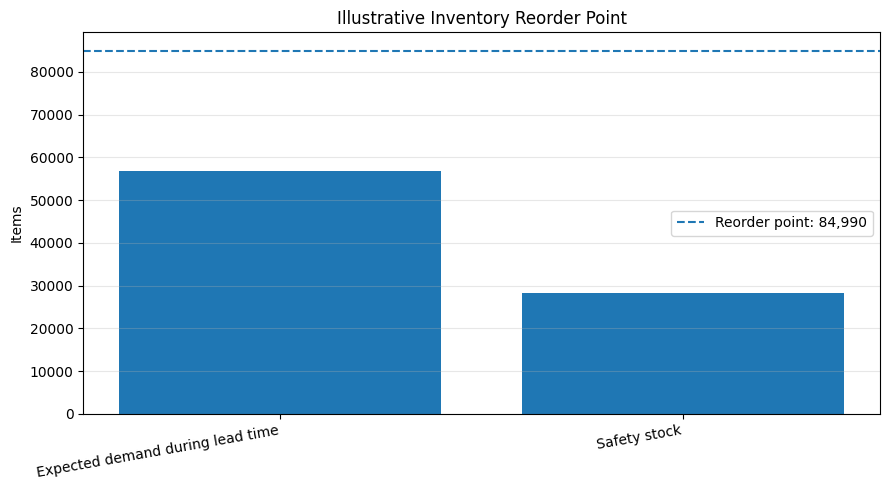

Reorder point: 84,990 items


In [11]:

inventory_components = pd.Series({
    "Expected demand during lead time": lead_time_demand,
    "Safety stock": safety_stock
})

plt.figure(figsize=(9, 5))
plt.bar(
    inventory_components.index,
    inventory_components.values
)
plt.axhline(
    reorder_point,
    linestyle="--",
    label=f"Reorder point: {reorder_point:,.0f}"
)

plt.title("Illustrative Inventory Reorder Point")
plt.ylabel("Items")
plt.xticks(rotation=10, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Reorder point: {reorder_point:,.0f} items")


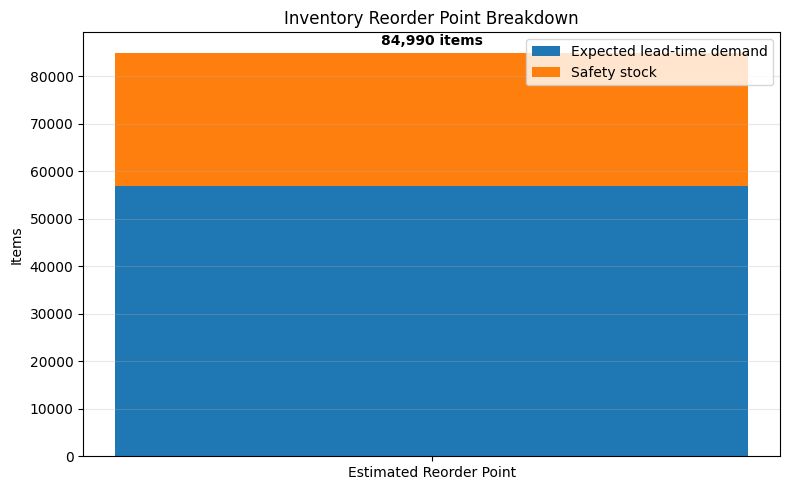

In [12]:

plt.figure(figsize=(8, 5))

plt.bar(
    ["Estimated Reorder Point"],
    [lead_time_demand],
    label="Expected lead-time demand"
)

plt.bar(
    ["Estimated Reorder Point"],
    [safety_stock],
    bottom=[lead_time_demand],
    label="Safety stock"
)

plt.text(
    0,
    reorder_point + 1500,
    f"{reorder_point:,.0f} items",
    ha="center",
    fontweight="bold"
)

plt.title("Inventory Reorder Point Breakdown")
plt.ylabel("Items")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
